# Etapa II: pronóstico sectorial sencillo

Comparación de oriente y sur con **Subidas_Promedio** del DTPM. Unidad: sector × tipo de día × franja de 30 minutos. Se pronostica con media histórica y se contrasta con el último observado. Las cantidades se convierten en alto, medio, bajo o nulo mediante umbrales históricos. Etapas, Viajes y geografía se reservan para una fase posterior.

Los sectores son una agrupación analítica de 6 y 10 comunas. No se corrige evasión ni se ajusta por población u oferta.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Etapa_02/resultados/panel_demanda_bus_modelo.csv").exists())
sys.path.insert(0, str(PROJECT_ROOT / "Etapa_02/codigo"))
from pronostico_sectorial_simple import main

main()
RESULTS = PROJECT_ROOT / "Etapa_02/resultados/sectorial_simple"


periodo  sector           metodo   n        MAE  WAPE_pct  acierto_etiqueta_pct  altos_reales  altos_detectados
2026-04 Oriente  Media histórica 135 618.231358  7.782967             83.703704            66                61
2026-04 Oriente Último observado 135 781.481481  9.838136             83.703704            66                60
2026-04     Sur  Media histórica 117 509.513960  9.128728             88.034188            14                12
2026-04     Sur Último observado 117 509.297436  9.124849             88.888889            14                12
Umbrales: 392.15555555555557 962.5177777777778 | Franjas positivas de calibración: 768
Autocontroles: cobertura, fronteras de etiquetas y ausencia de información futura: OK


## Evaluación temporal

La media usa solo antecedentes completos de la misma combinación. Un agregado sectorial incompleto no se usa como antecedente ni objetivo. Se excluyen también las franjas sin historial. Cada prueba utiliza cortes y umbrales anteriores al corte evaluado. Se comprueba automáticamente que cambiar valores futuros no altera pronósticos ni umbrales.

Abril de 2026 ya se había revisado en el avance anterior, por lo que esta evaluación es retrospectiva. El MAE nuevo corresponde a sumas sectoriales y no es comparable con el MAE comunal del avance original.


In [2]:
metrics = pd.read_csv(RESULTS / "metricas.csv")
print(metrics.to_string(index=False))
print("\nMatriz de etiquetas, media histórica:")
print(pd.read_csv(RESULTS / "confusion_etiquetas_abril_2026.csv").to_string(index=False))


periodo  sector           metodo   n        MAE  WAPE_pct  acierto_etiqueta_pct  altos_reales  altos_detectados
2025-04 Oriente  Media histórica 131 864.731298 10.829759             82.442748            66                59
2025-04 Oriente Último observado 131 864.731298 10.829759             82.442748            66                59
2025-04     Sur  Media histórica 119 788.349580 14.924854             84.033613            12                10
2025-04     Sur Último observado 119 788.349580 14.924854             84.033613            12                10
2025-11 Oriente  Media histórica 134 459.447015  5.771549             94.029851            74                74
2025-11 Oriente Último observado 134 738.976119  9.282979             81.343284            74                60
2025-11     Sur  Media histórica 119 283.399160  5.305888             97.478992            12                12
2025-11     Sur Último observado 119 423.522689  7.929325             86.554622            12           

## Pronóstico y observación en días laborales

Se grafican únicamente objetivos completos con historial. Las líneas unen las franjas disponibles. Las ausencias permanecen identificadas y no se interpretan como demanda nula.


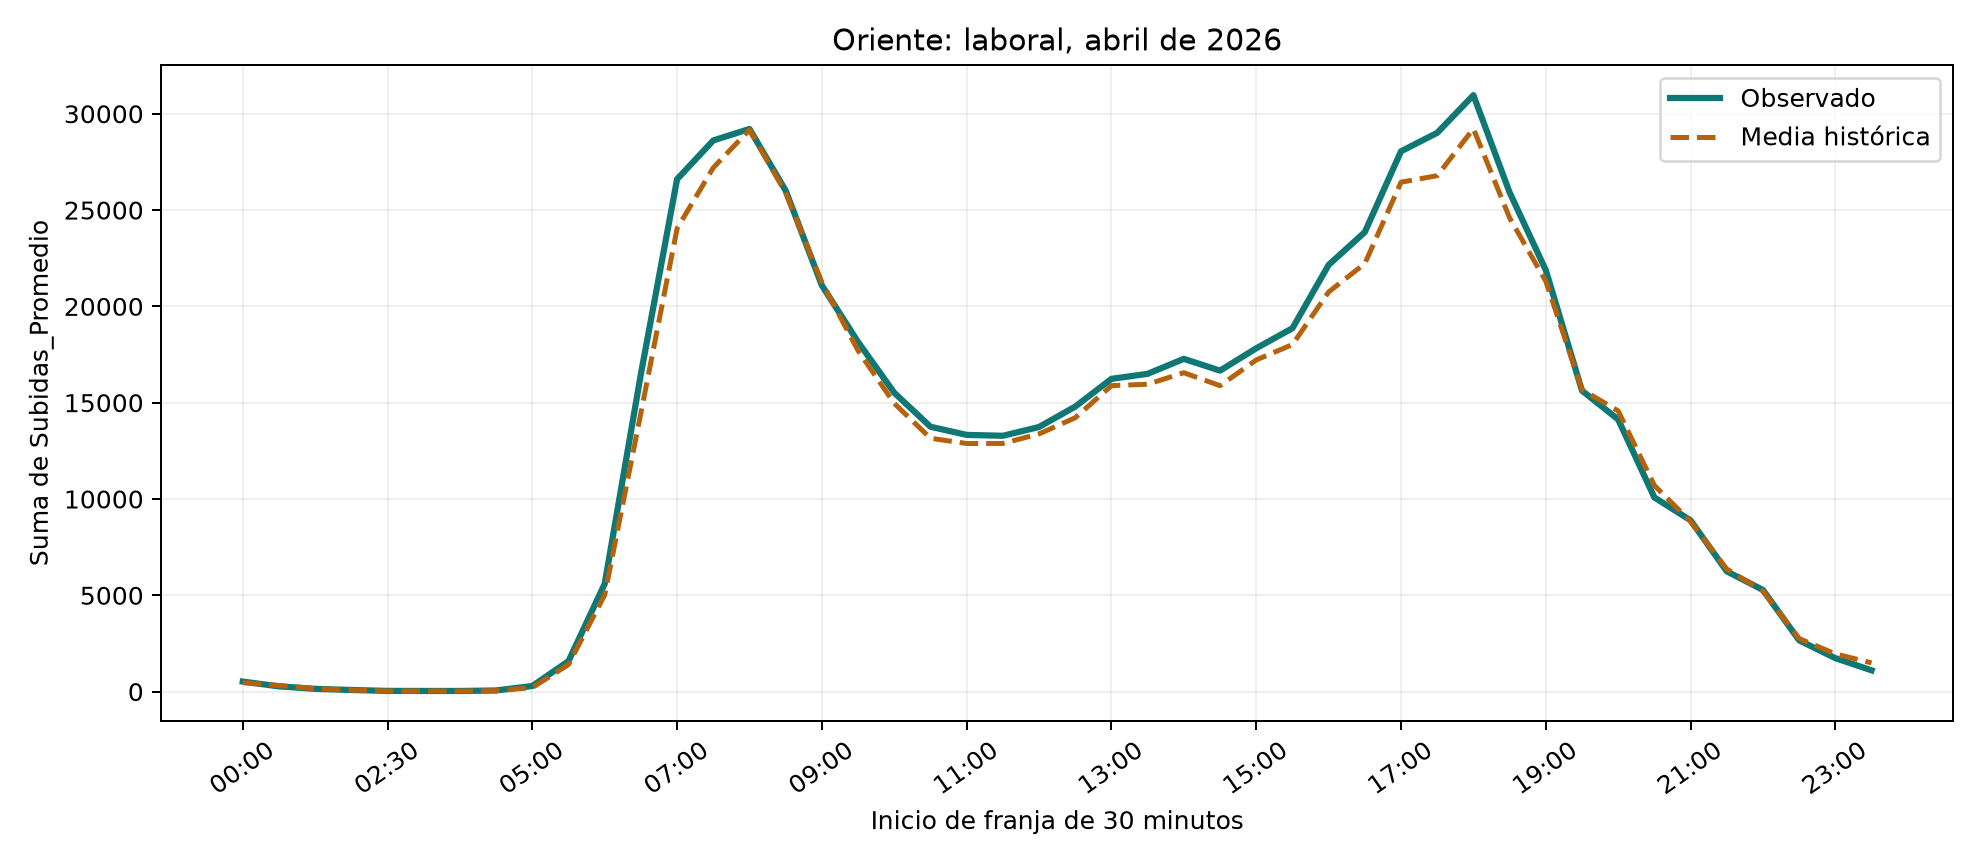

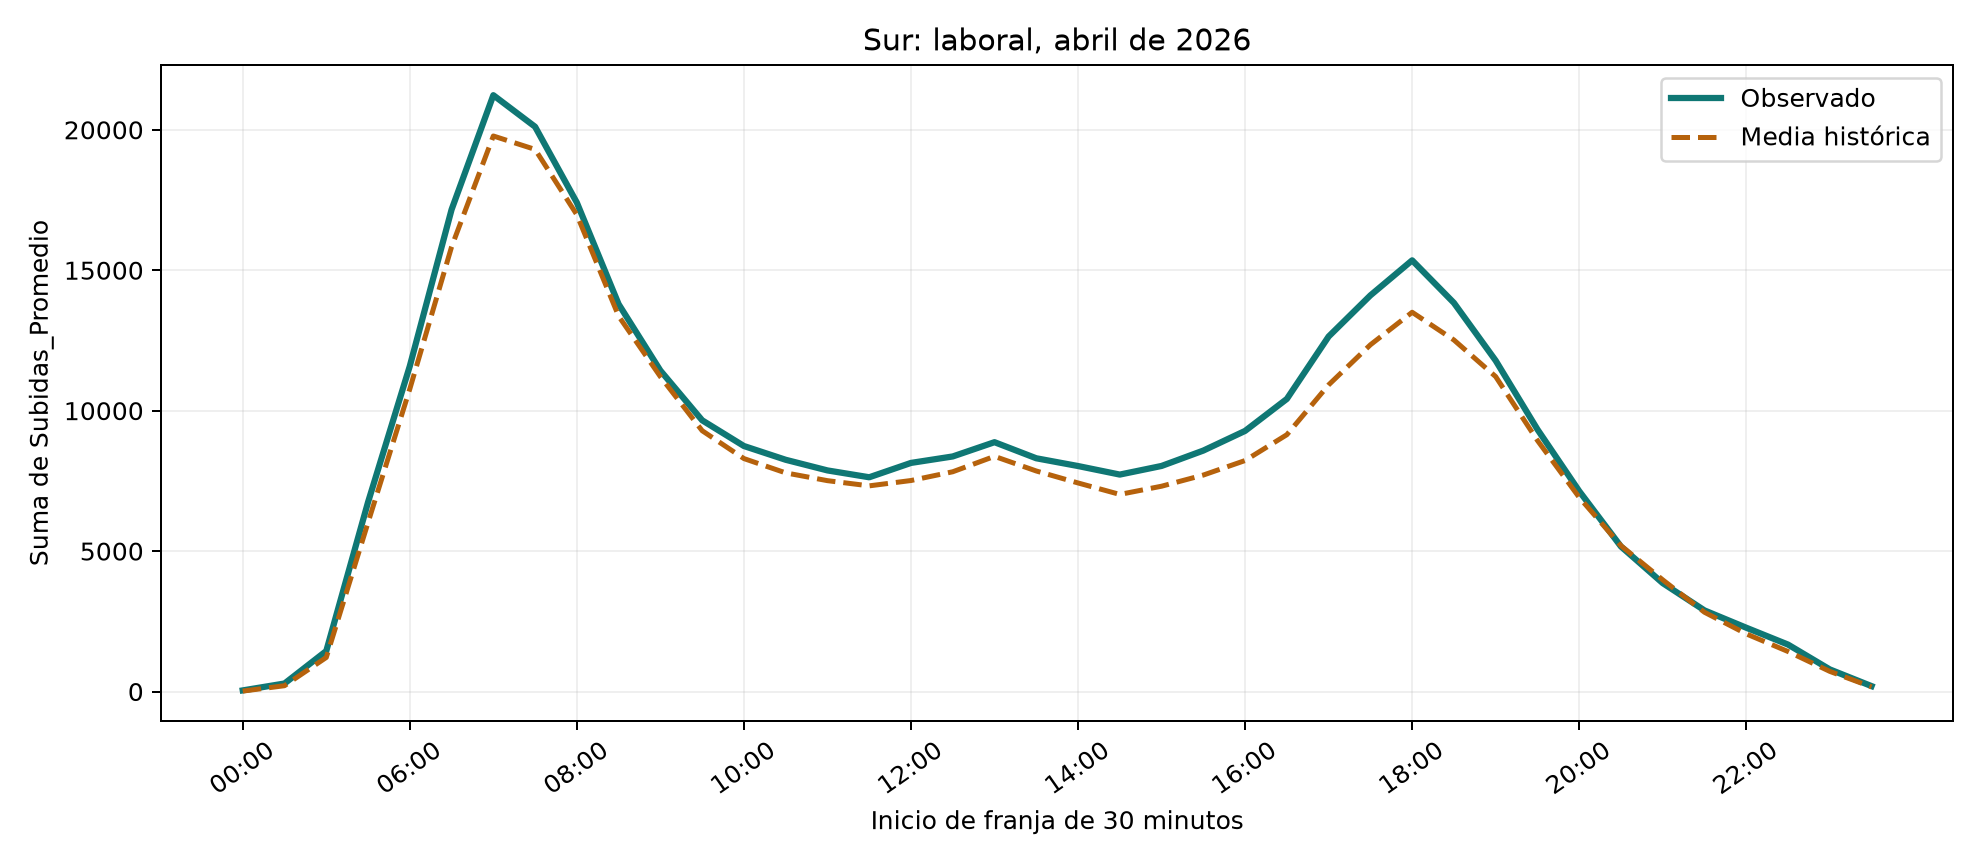

In [3]:
for sector in ["oriente", "sur"]:
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.imshow(plt.imread(RESULTS / f"pronostico_{sector}.png"))
    ax.axis("off")
    plt.show()


## Lectura de los resultados

En abril de 2026, la media mejora al último observado en oriente. En el sur ambos métodos dan resultados prácticamente iguales. Las etiquetas coinciden en 113 de 135 franjas evaluables de oriente (83,7 %) y 103 de 117 del sur (88,0 %). Se revisan también los errores por nivel para no ocultar fallos en grupos específicos. No existen franjas sectoriales nulas observadas y completas en estos cortes.

Los perfiles comparten dos puntas. El sur concentra más proporción entre 06:00 y 09:00 y oriente entre 16:00 y 20:00. Esto orienta una revisión de oferta que necesita datos de capacidad y ocupación antes de recomendar frecuencias.
